# S3 core STAR — institutional tearsheet

Frozen core STAR from `s3_core_star_stack.json`. One full-sample backtest, then **OOS-first** reporting after `RESEARCH_IS_END_S3`.

**Contract:** signal at close `t` → fill at open `t+1`. Costs follow `COST_PROFILE_STAR` / `config_from_stack`.


## 0. Imports & Config


In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "01_data", "ingestion")):
    parent = os.path.dirname(ROOT)
    if parent == ROOT:
        break
    ROOT = parent
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from backtest.s3_fx_trend.report import load_star_stack
from backtest.s3_fx_trend.research import (
    RESEARCH_IS_END_S3,
    config_from_stack,
    n_trials_ledger_total,
    star_stack_path,
)
from backtest.s3_fx_trend.runner import run_s3_backtest
from backtest.s3_fx_trend.tearsheet import (
    beta_corr_to_benchmark,
    bootstrap_sharpe_ci,
    check_fill_timing,
    cost_stress_sharpes,
    cvar,
    daily_regime_performance,
    equity_from_returns,
    export_s3_period_returns,
    extreme_trades,
    max_consecutive_losers,
    monthly_returns,
    oos_headline_metrics,
    pair_pnl_attribution,
    pair_scorecard,
    plot_drawdown,
    plot_equity_net_gross,
    plot_event_grid,
    plot_losing_months,
    plot_monthly_heatmap,
    plot_rolling_sharpe,
    plot_static_weekly_overlay,
    split_returns_at_is_end,
    spy_daily_returns,
    utilization_stats,
    weekly_overlay_frame,
    write_core_star_tearsheet_pdf,
)
from data.processing.s3_fx_price_panel import price_panel_path, s3_data_dir
from strategies.s3_fx_trend.metrics import (
    load_s1_period_returns,
    load_s2_period_returns,
    metrics_from_returns,
)

SLEEVE = "core"
IS_END = pd.Timestamp(RESEARCH_IS_END_S3)
DATA_DIR = s3_data_dir(ROOT)
ARTIFACTS = os.path.join(ROOT, "04_backtest", "s3_fx_trend", "artifacts")
os.makedirs(ARTIFACTS, exist_ok=True)
STACK_PATH = star_stack_path(SLEEVE)
stack = load_star_stack(STACK_PATH)
N_STACK = n_trials_ledger_total(sleeve=SLEEVE)
print(STACK_PATH)
print(f"IS_END={IS_END.date()}  n_trials_local=1  n_trials_stack={N_STACK}")
display(pd.Series(stack, name="value").to_frame())


C:\Users\User\Desktop\ML Algorithmic Trading\Portfolio 26\trading_portfolio\04_backtest\s3_fx_trend\artifacts\s3_core_star_stack.json
IS_END=2019-12-31  n_trials_local=1  n_trials_stack=40


,value
PAIRS_STAR,None
BAR_STAR,None
SIGNAL_FAMILY_STAR,None
TSMOM_LOOKBACKS_STAR,None
TSMOM_BLEND_STAR,None
DONCHIAN_N_STAR,None
DONCHIAN_HL_SOURCE_STAR,None
PAIR_VT_STAR,pair_vt
BOOK_VT_STAR,pair_plus_book_vt
VT_TARGET_ANN_VOL_STAR,None


## 1. Contract


In [2]:
print("Timing: signal at close t → fill open t+1")
print("Costs: COST_PROFILE_STAR / A_FX_OANDA_S3")
print("Day boundary: 17:00 America/New_York")
print("Sealed OOS: date >", IS_END.date())


Timing: signal at close t → fill open t+1
Costs: COST_PROFILE_STAR / A_FX_OANDA_S3
Day boundary: 17:00 America/New_York
Sealed OOS: date > 2019-12-31


## 2. Run


In [3]:
path = price_panel_path("1d", data_dir=DATA_DIR)
if not os.path.isfile(path):
    raise FileNotFoundError(path)
panel = pd.read_parquet(path)
panel["date"] = pd.to_datetime(panel["date"])

rates_path = os.path.join(DATA_DIR, "g10_policy_rates.parquet")
rates = pd.read_parquet(rates_path) if os.path.isfile(rates_path) else pd.DataFrame()
reer_path = os.path.join(DATA_DIR, "bis_reer_monthly.parquet")
reer = pd.read_parquet(reer_path) if os.path.isfile(reer_path) else pd.DataFrame()

cfg = config_from_stack(stack)
s1_weekly = load_s1_period_returns()
s2_daily = load_s2_period_returns()
if s1_weekly.empty:
    warnings.warn("S1 period returns missing — corr_to_s1 / weekly overlay incomplete")
if s2_daily.empty:
    warnings.warn("S2 period returns missing — corr_to_s2 / weekly overlay incomplete")

spy = spy_daily_returns(panel["date"].min(), panel["date"].max())
full_res = run_s3_backtest(
    panel,
    cfg,
    rates_df=rates if not rates.empty else None,
    reer_df=reer if not reer.empty else None,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
full_net = full_res.returns
full_gross = full_res.returns_gross
is_net, oos_net = split_returns_at_is_end(full_net, IS_END)
_, oos_gross = split_returns_at_is_end(full_gross, IS_END)
trades = full_res.pair_trades.copy() if full_res.pair_trades is not None else pd.DataFrame()
if not trades.empty and "entry_date" in trades.columns:
    trades["entry_date"] = pd.to_datetime(trades["entry_date"])
    oos_trades = trades.loc[trades["entry_date"] > IS_END].copy()
else:
    oos_trades = trades
print("full", len(full_net), "IS", len(is_net), "OOS", len(oos_net))
print(cfg)


full 5728 IS 3976 OOS 1752
S3SimConfig(pairs=('EURUSD', 'USDJPY', 'GBPUSD', 'USDCHF', 'USDCAD', 'AUDUSD', 'NZDUSD'), bar='1d', day_boundary_tz='America/New_York', day_boundary_hour=17, signal_family='tsmom', tsmom_lookbacks=(21, 63, 252), tsmom_blend='single_3m', donchian_n=55, donchian_hl_source='daily_ny_close', pair_vt=True, book_vt=True, vt_target_ann_vol=0.1, conviction_scaling='sign', weak_signal_flat_z=0.0, rebalance_band=0.0, carry_mode='tilt', carry_refresh='weekly', value_mode='off', value_refresh='monthly', carry_agree_scale=1.5, carry_disagree_scale=0.75, value_agree_scale=1.25, value_disagree_scale=0.75, spike_mode='both', spike_threshold_sigmas=2.0, corr_conflict_mode='off', corr_gate_threshold=0.85, currency_cap_gross_pct=0.5, cost_profile='A_FX_OANDA_S3', include_swap=True, financing_spread_bps_annual=50.0, cost_multiplier=1.0, event_z_gate=1.0, event_impact_min=2, event_hold_bars=1, event_bar='1d', surprise_sizing=False)


## 3. Full-sample glance (then stop using it)


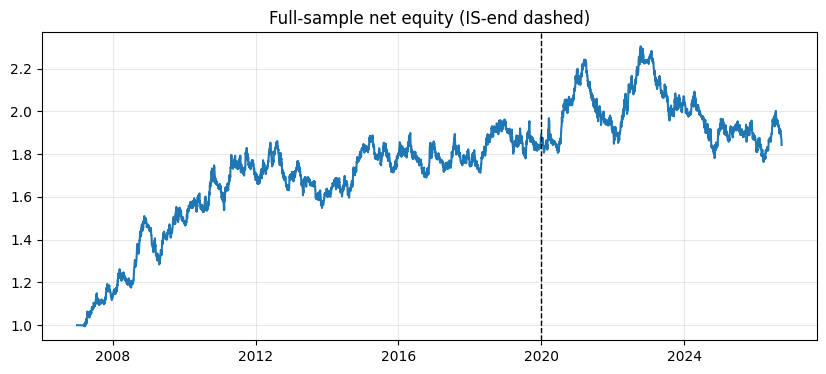

,value
is_sharpe,0.499485
oos_sharpe,0.002251
decay_ratio,0.004507


In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
eq = equity_from_returns(full_net)
ax.plot(eq.index, eq.values)
ax.axvline(IS_END, color="k", ls="--", lw=1)
ax.set_title("Full-sample net equity (IS-end dashed)")
ax.grid(True, alpha=0.3)
plt.show()

is_m = metrics_from_returns(is_net)
oos_m = metrics_from_returns(oos_net)
decay = pd.Series(
    {
        "is_sharpe": is_m["ann_sharpe"],
        "oos_sharpe": oos_m["ann_sharpe"],
        "decay_ratio": (
            float(oos_m["ann_sharpe"] / is_m["ann_sharpe"])
            if np.isfinite(is_m["ann_sharpe"]) and abs(is_m["ann_sharpe"]) > 1e-12
            else float("nan")
        ),
    }
)
display(decay.to_frame("value"))


## 4. OOS headline


In [5]:
headline = oos_headline_metrics(
    oos_net,
    oos_gross,
    trades=oos_trades,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
    spy_daily=spy if not spy.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
display(headline.to_frame("OOS"))


,OOS
ann_sharpe_net,0.002251
ann_sharpe_gross,0.140667
sortino,0.003833
calmar,-0.009903
max_drawdown,-0.234709
cagr,-0.002324
total_return,-0.016048
psr,0.537524
dsr_local,0.537524
dsr_stack,0.018070


## 5. OOS standalone performance

### 5.1 OOS equity (net vs gross)


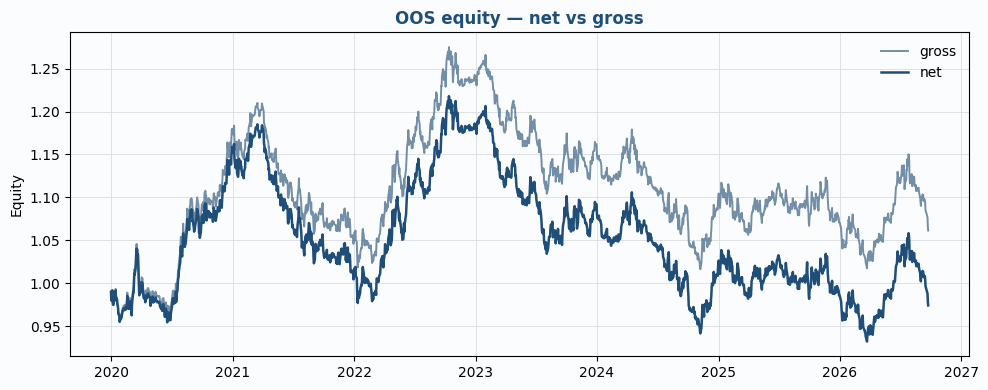

In [6]:
fig = plot_equity_net_gross(oos_net, oos_gross, title="OOS equity — net vs gross")
plt.show()


### 5.2 Drawdown


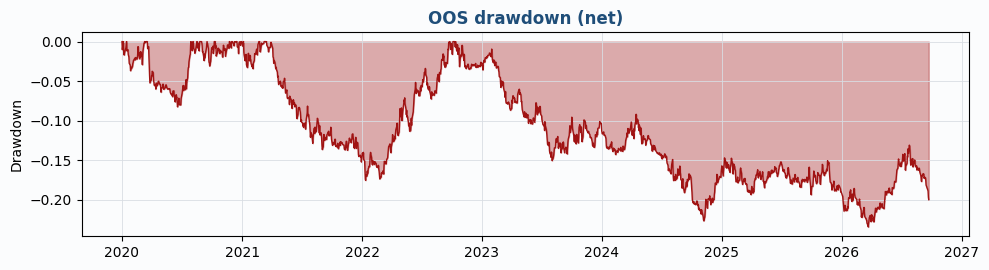

In [7]:
fig = plot_drawdown(oos_net, title="OOS drawdown (net)")
plt.show()


### 5.3 Rolling Sharpe


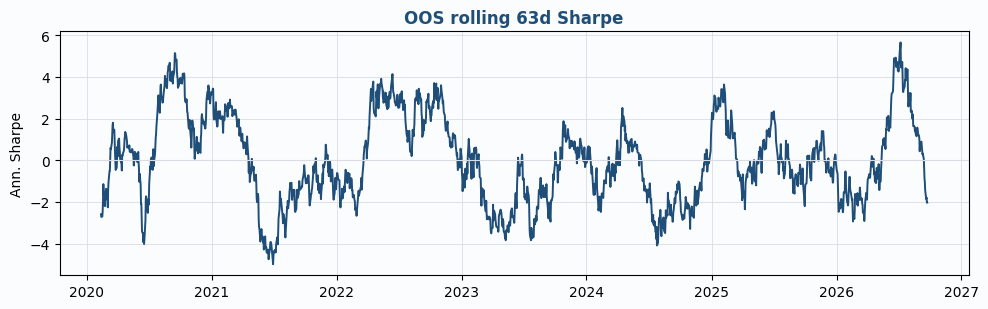

In [8]:
fig = plot_rolling_sharpe(oos_net, window=63, title="OOS rolling 63d Sharpe")
plt.show()


### 5.4 Monthly heatmap


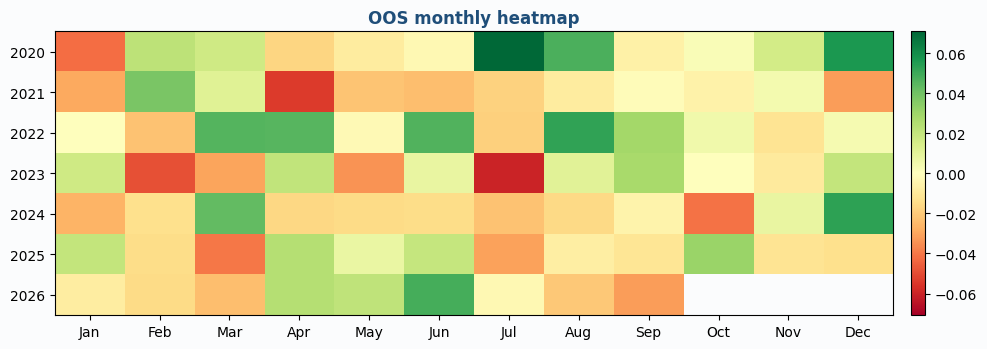

In [9]:
oos_monthly = monthly_returns(oos_net)
fig = plot_monthly_heatmap(oos_monthly, title="OOS monthly heatmap")
plt.show()


### 5.5 Return distribution


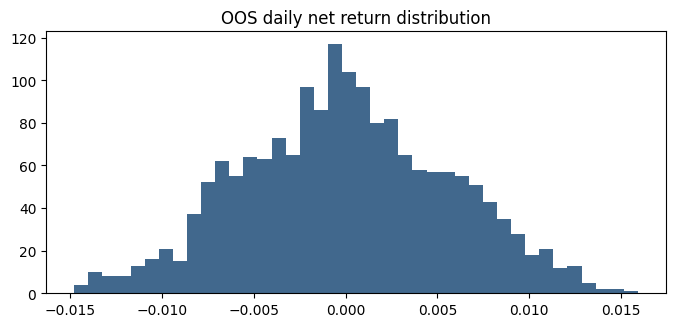

,ret
2022-04-19,-0.014773
2024-08-06,-0.014713
2025-09-28,-0.014447
2026-07-14,-0.014294
2021-06-16,-0.013993
2022-01-10,-0.013897
2026-07-29,-0.013787
2025-09-25,-0.013576
2021-01-14,-0.013549
2020-03-23,-0.013515


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(oos_net.dropna(), bins=40, color="#1f4e79", alpha=0.85)
ax.set_title("OOS daily net return distribution")
plt.show()
worst_days = oos_net.nsmallest(10).to_frame("ret")
display(worst_days)


## 6. Overlay (secondary)


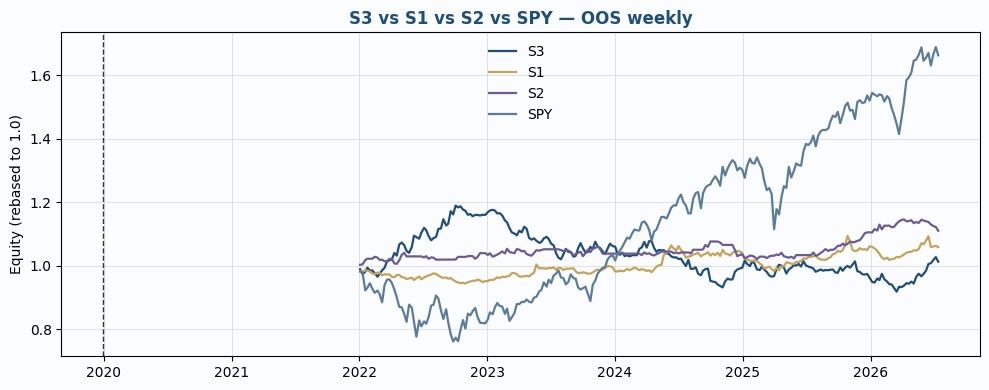

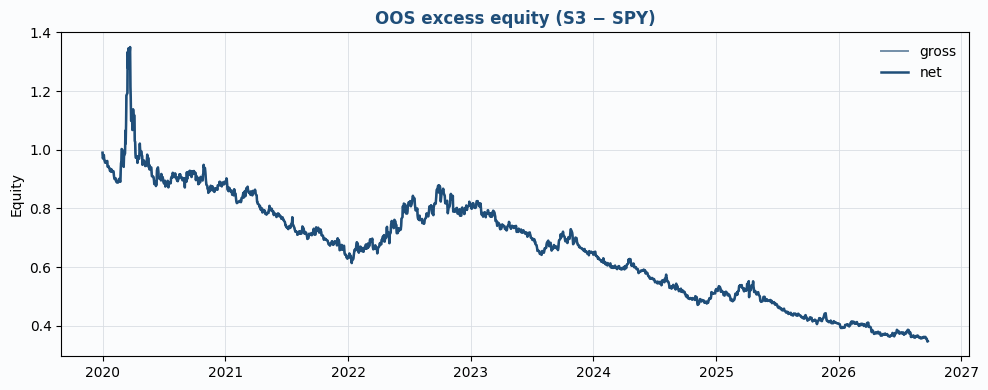

,value
beta,-0.019990
corr,-0.044768
n,1348.000000


In [11]:
weekly_full = weekly_overlay_frame(
    full_net,
    s1_weekly,
    s2_daily=s2_daily if not s2_daily.empty else None,
    spy_daily=spy if not spy.empty else None,
)
weekly_oos = weekly_overlay_frame(
    oos_net,
    s1_weekly,
    s2_daily=s2_daily if not s2_daily.empty else None,
    spy_daily=spy if not spy.empty else None,
)
fig = plot_static_weekly_overlay(
    weekly_oos if not weekly_oos.empty else weekly_full,
    title="S3 vs S1 vs S2 vs SPY — OOS weekly",
    is_end=IS_END,
)
plt.show()

spy_oos = spy.reindex(oos_net.index).fillna(0.0)
excess = (oos_net.fillna(0.0) - spy_oos).rename("excess")
fig = plot_equity_net_gross(excess, excess, title="OOS excess equity (S3 − SPY)")
plt.show()
display(pd.Series(beta_corr_to_benchmark(oos_net, spy), name="value").to_frame())


## 7. OOS losing months


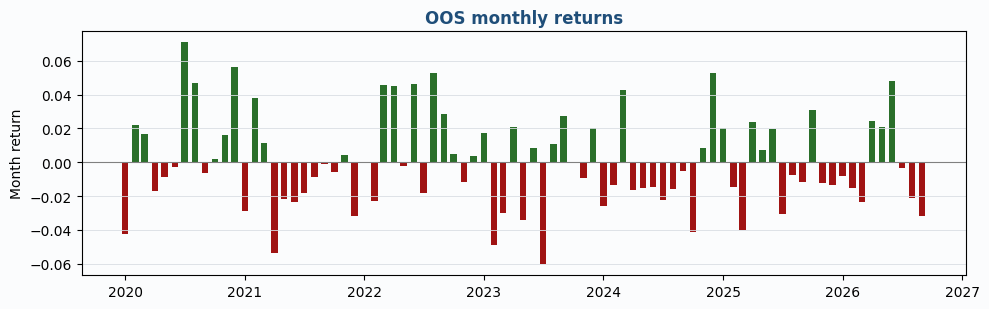

,monthly_return
2023-07-01,-0.060249
2021-04-01,-0.053737
2023-02-01,-0.048977
2020-01-01,-0.042116
2024-10-01,-0.041036
2025-03-01,-0.040196
2023-05-01,-0.034038
2021-12-01,-0.031593
2026-09-01,-0.031565
2025-07-01,-0.030640


In [12]:
fig = plot_losing_months(oos_monthly, title="OOS monthly returns")
plt.show()
display(oos_monthly.sort_values().head(10).to_frame("monthly_return"))


## 8. OOS regimes


In [13]:
is_dates = pd.DatetimeIndex(is_net.index)
regimes = daily_regime_performance(oos_net, spy, is_dates)
display(regimes["vol_cutpoints"].to_frame("value"))
display(regimes["market"])
display(regimes["vol"])


,value
q33,0.007454
q66,0.010725


,n,mean_return,total_return,sharpe,win_rate
regime,,,,,
Down,607,0.000143,0.080132,0.401495,0.514003
Up,741,-0.000124,-0.098522,-0.344071,0.491228


,n,mean_return,total_return,sharpe,win_rate
regime,,,,,
High,442,0.000421,0.195670,1.167029,0.529412
Low,392,-0.000344,-0.131301,-0.979803,0.471939
Mid,514,-0.000109,-0.062543,-0.303197,0.500000


## 9. Event study


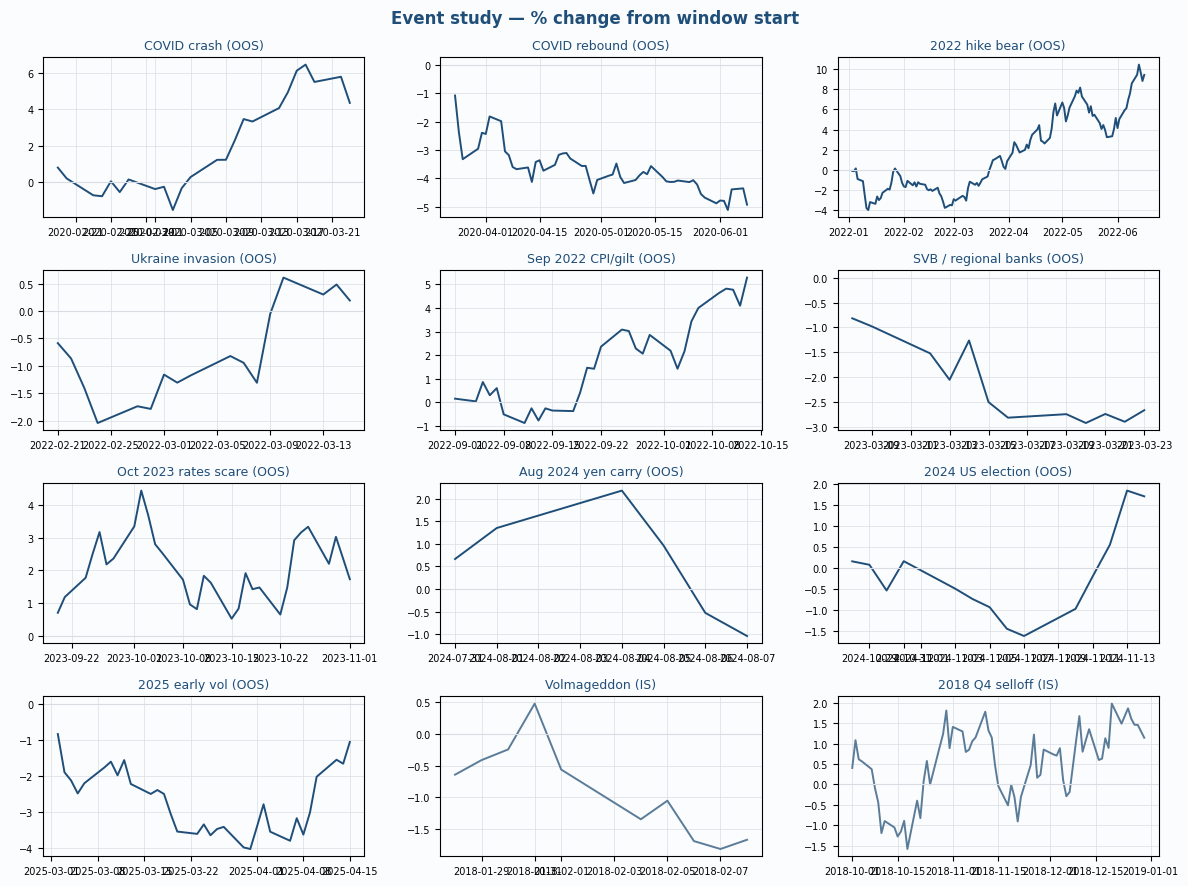

In [14]:
fig = plot_event_grid(full_net, is_end=IS_END)
plt.show()


## 10. OOS pair scorecard


,pair,ann_sharpe_net,ann_sharpe_gross,max_drawdown,n_trades,cost_bps_year,n_days
1,USDJPY,0.556642,0.458792,-0.206098,76,20.874981,1748
4,USDCAD,0.134803,0.211067,-0.296550,97,49.230138,1747
2,GBPUSD,0.014605,0.107754,-0.319262,105,42.307664,1747
0,EURUSD,-0.076105,-0.029312,-0.326482,114,43.556634,1747
3,USDCHF,-0.199840,-0.141569,-0.344264,106,54.652642,1747
5,AUDUSD,-0.225237,-0.149757,-0.458683,129,54.864328,1747
6,NZDUSD,-0.646907,-0.541803,-0.554409,127,65.755347,1751


,oos_total_return
NZDUSD,-0.440659
AUDUSD,-0.229480
USDCHF,-0.191015
EURUSD,-0.114371
GBPUSD,-0.037391
USDCAD,0.064772
USDJPY,0.597857


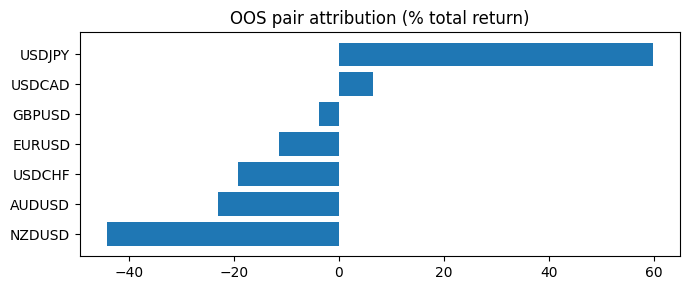

In [15]:
scorecard = pair_scorecard(full_res.book, date_min=IS_END + pd.Timedelta(days=1))
attr = pair_pnl_attribution(full_res.book, date_min=IS_END + pd.Timedelta(days=1))
display(scorecard.sort_values("ann_sharpe_net", ascending=False))
display(attr.to_frame("oos_total_return"))
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(attr.index), 100.0 * attr.values)
ax.set_title("OOS pair attribution (% total return)")
plt.tight_layout()
plt.show()


## 11. Trades — losing first


In [16]:
best, worst = extreme_trades(oos_trades, full_res.book, n=5)
display(worst)
display(best)


,pair_id,side_label,entry_date,exit_date,pnl_pct,exit_reason,hold_bars
0,GBPUSD,long,2022-02-07,2022-03-06,-0.064969,flip,19
1,NZDUSD,long,2024-06-11,2024-07-24,-0.064555,flip,31
2,AUDUSD,long,2025-03-17,2025-04-06,-0.058518,flip,14
3,USDJPY,long,2026-05-07,2026-08-02,-0.052203,flip,61
4,EURUSD,short,2026-06-17,2026-08-19,-0.050563,flip,45


,pair_id,side_label,entry_date,exit_date,pnl_pct,exit_reason,hold_bars
0,USDJPY,long,2022-02-23,2022-11-24,0.352127,flip,196
1,EURUSD,short,2022-02-23,2022-11-10,0.221816,flip,186
2,AUDUSD,short,2020-01-27,2020-05-25,0.213711,flip,85
3,USDJPY,long,2023-04-10,2023-12-03,0.203543,flip,169
4,USDCAD,long,2020-02-25,2020-06-04,0.176815,flip,72


## 12. Friction


In [17]:
w = full_res.book.weights
if w is not None and not w.empty:
    w = w.loc[pd.to_datetime(w.index) > IS_END]
util = utilization_stats(oos_net, oos_trades, weights=w)
display(util.to_frame("value"))

panel_oos = panel.loc[panel["date"] > IS_END].copy()
stress = cost_stress_sharpes(
    panel_oos,
    cfg,
    multipliers=(1.0, 1.5, 2.0),
    rates_df=rates if not rates.empty else None,
    reer_df=reer if not reer.empty else None,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
display(stress)


,value
pct_days_nonzero,1.000000
n_trades,754.000000
mean_gross_exposure,10.570911


,cost_multiplier,ann_sharpe_net,ann_sharpe_gross,max_drawdown,cost_bps_per_year,n_entries
0,1.0,0.072289,0.209879,-0.234709,331.697525,761
1,1.5,-0.027455,0.237386,-0.264167,497.546288,761
2,2.0,-0.137495,0.254699,-0.291273,663.395051,761


## 13. Tail + Sharpe CI


In [18]:
cvar_5 = cvar(oos_net, alpha=0.05)
sharpe_ci = bootstrap_sharpe_ci(oos_net)
tail = pd.Series(
    {
        "cvar_5": cvar_5,
        "max_consecutive_losers": max_consecutive_losers(oos_net),
        **sharpe_ci,
        "psr": headline.get("psr", float("nan")),
        "dsr_stack": headline.get("dsr_stack", float("nan")),
    }
)
display(tail.to_frame("value"))


,value
cvar_5,-0.011217
max_consecutive_losers,9.000000
sharpe,0.002251
ci_low,-0.746483
ci_high,0.743760
n_boot,2000.000000
psr,0.537524
dsr_stack,0.018070


## 14. Fill-timing assert


In [19]:
timing = check_fill_timing(oos_trades, panel)
display(timing.head())
print("all_ok rate", float(timing["all_ok"].mean()) if not timing.empty else float("nan"))


,pair,entry_date,signal_date,ok_signal_before_fill,ok_fill_has_open,ok_not_same_bar_close_fill,all_ok
0,EURUSD,2020-01-19,2020-01-16,True,True,True,True
1,EURUSD,2020-03-01,2020-02-27,True,True,True,True
2,EURUSD,2020-03-15,2020-03-12,True,True,True,True
3,EURUSD,2020-03-16,2020-03-15,True,True,True,True
4,EURUSD,2020-03-17,2020-03-16,True,True,True,True


all_ok rate 1.0


## 15. Export + PDF


In [20]:
returns_path = os.path.join(
    ROOT, "01_data", "data_files", "s3_fx_trend", "s3_period_returns.parquet"
)
export_s3_period_returns(oos_net, returns_path)
print("wrote", returns_path)

pdf_path = os.path.join(ARTIFACTS, "s3_core_star_tearsheet.pdf")
write_core_star_tearsheet_pdf(
    pdf_path,
    stack=stack,
    is_end=IS_END,
    full_net=full_net,
    oos_net=oos_net,
    oos_gross=oos_gross,
    headline=headline,
    weekly_full=weekly_full,
    weekly_oos=weekly_oos,
    spy_daily=spy,
    event_returns=full_net,
    scorecard=scorecard,
    attribution=attr,
    worst_trades=worst,
    best_trades=best,
    sharpe_ci=sharpe_ci,
    cvar_5=cvar_5,
)
print("wrote", pdf_path)


wrote c:\Users\User\Desktop\ML Algorithmic Trading\Portfolio 26\trading_portfolio\01_data\data_files\s3_fx_trend\s3_period_returns.parquet
wrote c:\Users\User\Desktop\ML Algorithmic Trading\Portfolio 26\trading_portfolio\04_backtest\s3_fx_trend\artifacts\s3_core_star_tearsheet.pdf
